# Imports

In [29]:
import os

cwd = os.getcwd()
os.chdir("/home/yoshi0428/PycharmProjects/osu-predict")

In [30]:
import json
import pickle
from collections import Counter
from datetime import datetime

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    GroupKFold,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

from beatmap_classifier.classifier.augment_faster import (
    augment_dataset,
    extract_movement_features_from_X,
)
from beatmap_classifier.classifier.cnn_model import CNNModel
from beatmap_classifier.classifier.utils_training import (
    get_additional_features,
    get_data,
    load_pytorch_models,
    pad_sequences_pt,
    plot_training_history,
    predict_proba,
    save_vector_normalization,
    train_and_evaluate,
)

# Model Testing

Go run test_model.py

# Initializing some Data

In [31]:
TOURNAMENT_MODS = {
    "nm1": "NM",
    "nm2": "NM",
    "nm3": "NM",
    "nm4": "NM",
    "nm5": "NM",
    "nm6": "NM",
    "hd1": "HD",
    "hd2": "HD",
    "hd3": "HD",
    "hr1": "HR",
    "hr2": "HR",
    "hr3": "HR",
    "dt1": "DT",
    "dt2_and_dt3": "DT",
    "dt4": "DT",
    "tiebreaker": "NM",
}

In [32]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

db_path = "./beatmap_classifier/unexpanded_beatmaps.db"

X, y, beatmap_ids = get_data(db_path)
raw_additional_features, normalized_additional_features = get_additional_features(
    db_path, y, beatmap_ids
)

# Precompute must scale vectors exactly like get_data() did, so save the
# scales next to the model (read by precompute_nm1-5.py and test_model.py).
save_vector_normalization(db_path, "./beatmap_classifier/models/eval/vector_normalization.json")

Max Vector Length: 500.0
Max Time Diff: 86087.0
Tournament-labeled beatmaps: 3922
Max Vector Count: 6309
Original beatmaps: 3922


{'max_time_diff': 86087.0, 'max_vector_length': 500.0}

In [33]:
# Get the mod associated with each tournament label
mods_flattened = [
    TOURNAMENT_MODS[label] if TOURNAMENT_MODS[label] else "NM" for label in y
]

raw_additional_features_array = np.array(
    [
        raw_additional_features[(beatmap_id, mod)]
        for beatmap_id, mod in zip(beatmap_ids, mods_flattened)
    ]
)

normalized_additional_features_array = np.array(
    [
        normalized_additional_features[(beatmap_id, mod)]
        for beatmap_id, mod in zip(beatmap_ids, mods_flattened)
    ]
)

In [34]:
(
    X_train,
    X_test,
    y_train,
    y_test,
    beatmap_ids_train,
    beatmap_ids_test,
) = train_test_split(
    X,
    y,
    beatmap_ids,
    test_size=0.2,
    random_state=42,
)

print(f"Final train size: {len(X_train)}")
print(f"Final test size:  {len(X_test)}")

Final train size: 3137
Final test size:  785


In [35]:
# Encode labels
label_encoder = LabelEncoder()
label_encoder.fit(y)

with open("./beatmap_classifier/models/eval/label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

y_train_numerical = label_encoder.transform(y_train)
y_test_numerical = label_encoder.transform(y_test)
num_classes = len(label_encoder.classes_)

y_train_numerical = torch.tensor(y_train_numerical, dtype=torch.long)
y_test_numerical = torch.tensor(y_test_numerical, dtype=torch.long)

# Pad sequences
sequence_lengths = np.array([len(seq) for seq in X])
max_length = int(np.percentile(sequence_lengths, 99))
max_length = 2 ** int(np.ceil(np.log2(max_length)))
max_length = min(max_length, 4096)

print(f"Using max sequence length: {max_length}")

X_train = pad_sequences_pt(X_train, maxlen=max_length, dtype=torch.float32)

X_test = pad_sequences_pt(X_test, maxlen=max_length, dtype=torch.float32)

print("Before metadata:")
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")

Using max sequence length: 4096
Before metadata:
X_train: torch.Size([3137, 4096, 8])
X_test:  torch.Size([785, 4096, 8])


In [36]:
class_counts = Counter(y_train_numerical.numpy())

for cls, count in sorted(class_counts.items()):
    print(f"Class {cls}: {count}")

print(dict(enumerate(label_encoder.classes_)))

Class 0: 703
Class 1: 710
Class 2: 731
Class 3: 608
Class 4: 385
{0: np.str_('nm1'), 1: np.str_('nm2'), 2: np.str_('nm3'), 3: np.str_('nm4'), 4: np.str_('nm5')}


In [37]:
# Extract geometric summary vectors for each row in X_train and X_test
movement_features_train = np.array(
    [extract_movement_features_from_X(X_train[i]) for i in range(len(X_train))],
    dtype=np.float32,
)

movement_features_test = np.array(
    [extract_movement_features_from_X(X_test[i]) for i in range(len(X_test))],
    dtype=np.float32,
)

# NOTICE THAT WE SWITCH FROM NORMALIZED TO RAW ADDITIONAL FEATURES
# BECAUSE XGBOOST DOESN'T NEED SCALING

# Extract SQLite metadata features corresponding to train/test IDs
mods_flattened_train = [TOURNAMENT_MODS.get(label, "NM") for label in y_train]

sql_features_train = np.array(
    [
        raw_additional_features[(b_id, mod)]
        for b_id, mod in zip(beatmap_ids_train, mods_flattened_train)
    ],
    dtype=np.float32,
)

mods_flattened_test = [TOURNAMENT_MODS.get(label, "NM") for label in y_test]

sql_features_test = np.array(
    [
        raw_additional_features.get((b_id, mod))
        for b_id, mod in zip(beatmap_ids_test, mods_flattened_test)
    ],
    dtype=np.float32,
)

# Concatenate (SQL metadata + Movement geometric summary)
X_additional_train = np.hstack([sql_features_train, movement_features_train])
X_additional_test = np.hstack([sql_features_test, movement_features_test])

print(f"Full meta tabular train shape: {X_additional_train.shape}")
print(f"Full meta tabular test shape:  {X_additional_test.shape}")

Full meta tabular train shape: (3137, 24)
Full meta tabular test shape:  (785, 24)


# CNN Model (SKIP TO XGBOOST IF DESIRED)

--- Training Meta Fold 1/5 ---
Epoch 1/50 - loss: 2.0940 - acc: 0.4703 - val_loss: 0.9441 - val_acc: 0.7357
Epoch 2/50 - loss: 1.0648 - acc: 0.6620 - val_loss: 0.8642 - val_acc: 0.7707
Epoch 3/50 - loss: 0.9821 - acc: 0.7122 - val_loss: 0.8054 - val_acc: 0.7946
Epoch 4/50 - loss: 0.9042 - acc: 0.7609 - val_loss: 0.8112 - val_acc: 0.8344
Epoch 5/50 - loss: 0.8713 - acc: 0.7872 - val_loss: 0.7818 - val_acc: 0.8217
Epoch 6/50 - loss: 0.8340 - acc: 0.8067 - val_loss: 0.7072 - val_acc: 0.8567
Epoch 7/50 - loss: 0.7848 - acc: 0.8258 - val_loss: 0.6686 - val_acc: 0.8885
Epoch 8/50 - loss: 0.7823 - acc: 0.8434 - val_loss: 0.7224 - val_acc: 0.8583
Epoch 9/50 - loss: 0.7655 - acc: 0.8481 - val_loss: 0.7018 - val_acc: 0.8646
Epoch 10/50 - loss: 0.7436 - acc: 0.8569 - val_loss: 0.6495 - val_acc: 0.8854
Epoch 11/50 - loss: 0.7304 - acc: 0.8625 - val_loss: 0.6383 - val_acc: 0.8949
Epoch 12/50 - loss: 0.7150 - acc: 0.8613 - val_loss: 0.6506 - val_acc: 0.8869
Epoch 13/50 - loss: 0.7039 - acc: 0.8749 -

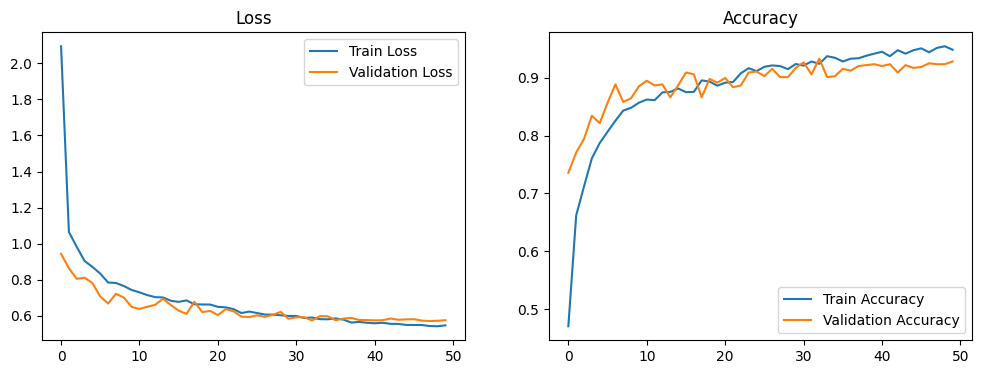

--- Training Meta Fold 2/5 ---
Epoch 1/50 - loss: 2.2727 - acc: 0.5145 - val_loss: 0.9958 - val_acc: 0.7229
Epoch 2/50 - loss: 1.0535 - acc: 0.6712 - val_loss: 0.9141 - val_acc: 0.7516
Epoch 3/50 - loss: 1.0073 - acc: 0.7154 - val_loss: 0.8492 - val_acc: 0.7914
Epoch 4/50 - loss: 0.9097 - acc: 0.7652 - val_loss: 0.7824 - val_acc: 0.8248
Epoch 5/50 - loss: 0.8975 - acc: 0.7728 - val_loss: 0.7956 - val_acc: 0.8137
Epoch 6/50 - loss: 0.8351 - acc: 0.8007 - val_loss: 0.8602 - val_acc: 0.7755
Epoch 7/50 - loss: 0.8106 - acc: 0.8143 - val_loss: 0.8641 - val_acc: 0.7787
Epoch 8/50 - loss: 0.7878 - acc: 0.8218 - val_loss: 0.7676 - val_acc: 0.8328
Epoch 9/50 - loss: 0.7579 - acc: 0.8454 - val_loss: 0.6784 - val_acc: 0.8806
Epoch 10/50 - loss: 0.7292 - acc: 0.8661 - val_loss: 0.7558 - val_acc: 0.8328
Epoch 11/50 - loss: 0.7400 - acc: 0.8581 - val_loss: 0.6821 - val_acc: 0.8694
Epoch 12/50 - loss: 0.7333 - acc: 0.8521 - val_loss: 0.6875 - val_acc: 0.8758
Epoch 13/50 - loss: 0.7150 - acc: 0.8589 -

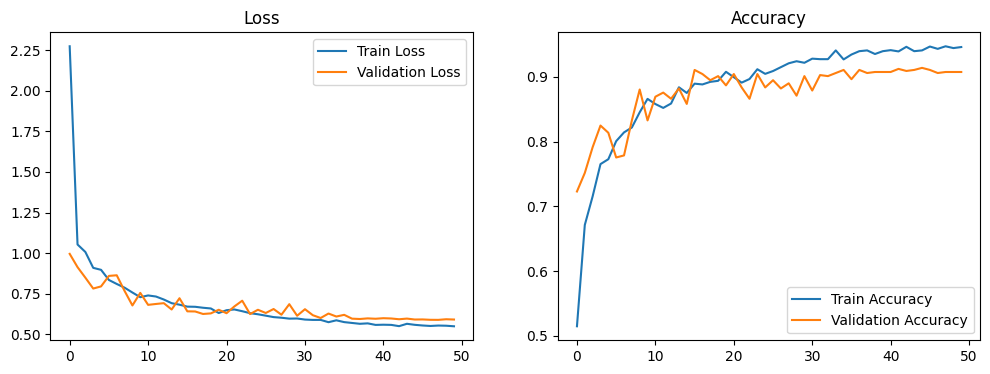

--- Training Meta Fold 3/5 ---
Epoch 1/50 - loss: 2.1622 - acc: 0.5127 - val_loss: 1.1166 - val_acc: 0.6029
Epoch 2/50 - loss: 1.0532 - acc: 0.6681 - val_loss: 0.9552 - val_acc: 0.7081
Epoch 3/50 - loss: 1.0145 - acc: 0.7048 - val_loss: 0.9237 - val_acc: 0.7384
Epoch 4/50 - loss: 0.9240 - acc: 0.7542 - val_loss: 0.8034 - val_acc: 0.7895
Epoch 5/50 - loss: 0.8563 - acc: 0.7841 - val_loss: 0.7904 - val_acc: 0.8102
Epoch 6/50 - loss: 0.8324 - acc: 0.8040 - val_loss: 0.7497 - val_acc: 0.8469
Epoch 7/50 - loss: 0.7992 - acc: 0.8319 - val_loss: 0.7383 - val_acc: 0.8421
Epoch 8/50 - loss: 0.7636 - acc: 0.8418 - val_loss: 0.7503 - val_acc: 0.8421
Epoch 9/50 - loss: 0.7597 - acc: 0.8534 - val_loss: 0.6844 - val_acc: 0.8676
Epoch 10/50 - loss: 0.7543 - acc: 0.8454 - val_loss: 0.7819 - val_acc: 0.8054
Epoch 11/50 - loss: 0.7526 - acc: 0.8566 - val_loss: 0.7248 - val_acc: 0.8166
Epoch 12/50 - loss: 0.7174 - acc: 0.8745 - val_loss: 0.6742 - val_acc: 0.8469
Epoch 13/50 - loss: 0.7214 - acc: 0.8645 -

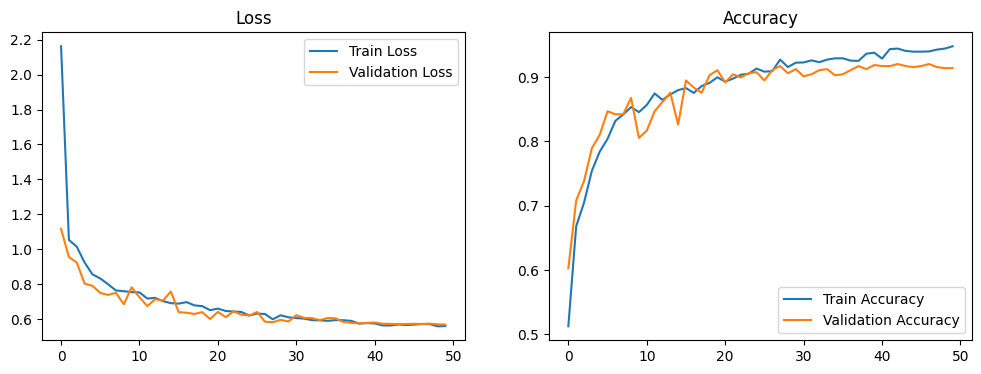

--- Training Meta Fold 4/5 ---
Epoch 1/50 - loss: 2.4298 - acc: 0.4992 - val_loss: 0.9804 - val_acc: 0.7145
Epoch 2/50 - loss: 1.0638 - acc: 0.6629 - val_loss: 0.9298 - val_acc: 0.7480
Epoch 3/50 - loss: 1.0064 - acc: 0.7048 - val_loss: 0.8774 - val_acc: 0.7592
Epoch 4/50 - loss: 0.9397 - acc: 0.7414 - val_loss: 0.8315 - val_acc: 0.7863
Epoch 5/50 - loss: 0.8897 - acc: 0.7793 - val_loss: 0.7953 - val_acc: 0.8038
Epoch 6/50 - loss: 0.8347 - acc: 0.8076 - val_loss: 0.7812 - val_acc: 0.8166
Epoch 7/50 - loss: 0.8364 - acc: 0.8016 - val_loss: 0.7882 - val_acc: 0.8198
Epoch 8/50 - loss: 0.7917 - acc: 0.8267 - val_loss: 0.7077 - val_acc: 0.8549
Epoch 9/50 - loss: 0.7630 - acc: 0.8486 - val_loss: 0.7201 - val_acc: 0.8389
Epoch 10/50 - loss: 0.7642 - acc: 0.8430 - val_loss: 0.7579 - val_acc: 0.8421
Epoch 11/50 - loss: 0.7467 - acc: 0.8542 - val_loss: 0.6821 - val_acc: 0.8644
Epoch 12/50 - loss: 0.7197 - acc: 0.8673 - val_loss: 0.6857 - val_acc: 0.8740
Epoch 13/50 - loss: 0.7200 - acc: 0.8606 -

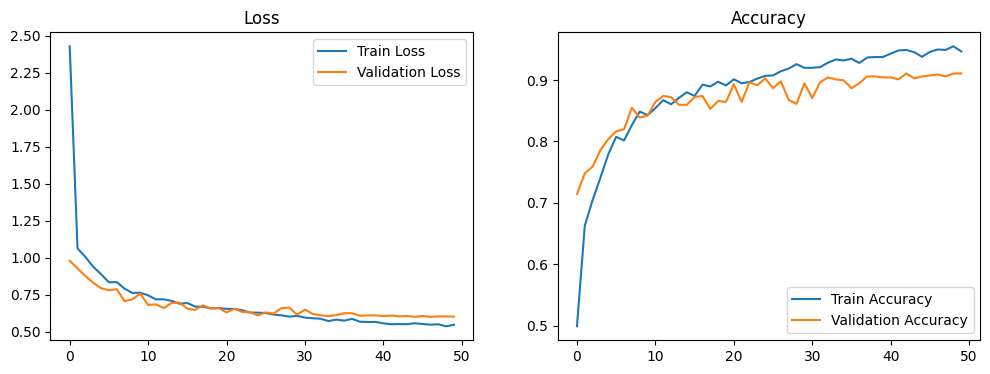

--- Training Meta Fold 5/5 ---
Epoch 1/50 - loss: 2.0291 - acc: 0.5414 - val_loss: 0.9678 - val_acc: 0.7416
Epoch 2/50 - loss: 1.0438 - acc: 0.6777 - val_loss: 0.8904 - val_acc: 0.7799
Epoch 3/50 - loss: 0.9887 - acc: 0.7060 - val_loss: 0.8742 - val_acc: 0.7496
Epoch 4/50 - loss: 0.9162 - acc: 0.7506 - val_loss: 0.8201 - val_acc: 0.8182
Epoch 5/50 - loss: 0.8697 - acc: 0.7880 - val_loss: 0.7367 - val_acc: 0.8405
Epoch 6/50 - loss: 0.8138 - acc: 0.8171 - val_loss: 0.6925 - val_acc: 0.8660
Epoch 7/50 - loss: 0.8106 - acc: 0.8151 - val_loss: 0.7932 - val_acc: 0.7959
Epoch 8/50 - loss: 0.7655 - acc: 0.8438 - val_loss: 0.6983 - val_acc: 0.8676
Epoch 9/50 - loss: 0.7590 - acc: 0.8351 - val_loss: 0.6650 - val_acc: 0.8820
Epoch 10/50 - loss: 0.7455 - acc: 0.8454 - val_loss: 0.6705 - val_acc: 0.8915
Epoch 11/50 - loss: 0.7030 - acc: 0.8725 - val_loss: 0.6761 - val_acc: 0.8724
Epoch 12/50 - loss: 0.7075 - acc: 0.8669 - val_loss: 0.6288 - val_acc: 0.8995
Epoch 13/50 - loss: 0.7079 - acc: 0.8606 -

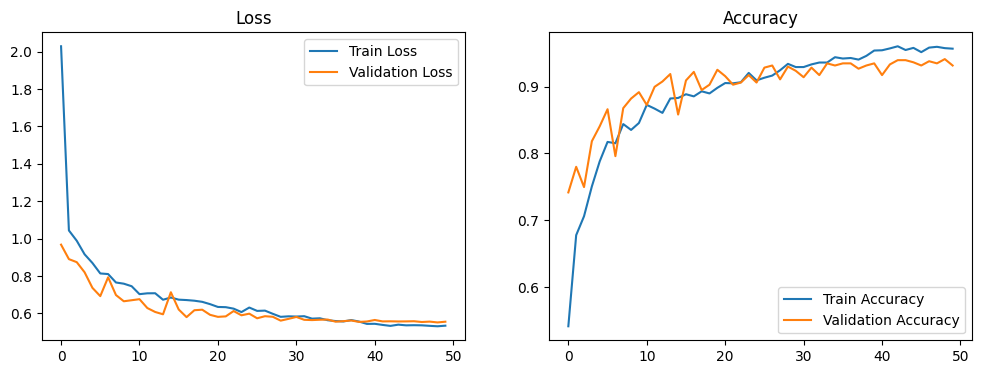

In [38]:
meta_bagging_models = []
beatmap_ids_train = np.array(beatmap_ids_train)

# Initialize empty matrix for clean Out-Of-Fold CNN probability predictions
oof_cnn_predictions = np.zeros((len(X_train), num_classes), dtype=np.float32)

# NOTE: groups are beatmap ids, which are unique, so this is plain KFold
# (mapset difficulties are NOT kept together)
gkf = GroupKFold(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(
    gkf.split(X_train, y_train_numerical, groups=beatmap_ids_train)
):
    print(f"--- Training Meta Fold {fold + 1}/5 ---")

    # Split raw unaugmented fold data
    X_fold_train, y_fold_train = X_train[train_idx], y_train_numerical[train_idx]
    X_fold_val, y_fold_val = X_train[val_idx], y_train_numerical[val_idx]

    # Convert validation fold to PyTorch Tensor (permuted to (B, C, L))
    X_fold_val = torch.as_tensor(X_fold_val, dtype=torch.float32).permute(0, 2, 1)
    y_fold_val = torch.as_tensor(y_fold_val, dtype=torch.long)

    X_fold_train = torch.as_tensor(X_fold_train, dtype=torch.float32).permute(0, 2, 1)

    # Train CNN model for this fold. Flips are applied randomly per batch
    # inside train_and_evaluate (random_flips=True), so no augment_dataset().
    model, history = train_and_evaluate(
        X_fold_train,
        y_fold_train,
        X_fold_val,
        y_fold_val,
        input_channels=X_fold_train.shape[1],
        num_classes=num_classes,
        max_length=max_length,
        learning_rate=0.001,
        dropout_rate=0.3,  # old: 0.5
        l2_reg=0.001,
        batch_size=32,  # old: 128 (32 was clearly better in CV)
        epochs=50,  # old: 30
        patience=15,
    )
    plot_training_history(history)
    meta_bagging_models.append(model)

    # Generate Out-of-Fold predictions for the unaugmented validation set ONLY
    probs = predict_proba(model, X_fold_val, device)

    # Store clean OOF predictions in the array
    oof_cnn_predictions[val_idx] = probs

In [39]:
os.makedirs("./beatmap_classifier/models/eval/bagged_models", exist_ok=True)

for i, model in enumerate(meta_bagging_models):
    torch.save(model.state_dict(), f"./beatmap_classifier/models/eval/bagged_models/bagged_cnn_model_{i}.pth")

np.save("./beatmap_classifier/models/eval/oof_cnn_predictions.npy", oof_cnn_predictions)
np.save("./beatmap_classifier/models/eval/y_train_numerical.npy", y_train_numerical)
np.save("./beatmap_classifier/models/eval/beatmap_ids_train.npy", np.array(beatmap_ids_train))

# XGBoost Meta Model

### Load Models and Data

In [40]:
model_kwargs = {
    "input_channels": 8,
    "num_classes": num_classes,
    "max_length": max_length,
    "dropout_rate": 0.3,
}

meta_bagging_models = load_pytorch_models(
    model_folder="./beatmap_classifier/models/eval/bagged_models",
    model_class=CNNModel,
    model_kwargs=model_kwargs,
    device=device,
)

oof_cnn_predictions = np.load("./beatmap_classifier/models/eval/oof_cnn_predictions.npy")
y_train_numerical = np.load("./beatmap_classifier/models/eval/y_train_numerical.npy")

print(f"Loaded {len(meta_bagging_models)} CNN models")

Loaded 5 CNN models


### Test the bagging models
92% is already pretty good, but we will see soon that we can improve it

In [41]:
# Generate Test probabilities by averaging predictions across all fold models
X_test_tensor = torch.as_tensor(X_test, dtype=torch.float32).permute(0, 2, 1)
test_probs_list = [
    predict_proba(model, X_test_tensor, device) for model in meta_bagging_models
]

bagged_test_predictions = np.mean(test_probs_list, axis=0)
bagged_test_predictions_numerical = np.argmax(bagged_test_predictions, axis=1)

score = accuracy_score(y_test_numerical, bagged_test_predictions_numerical)
cm = confusion_matrix(y_test_numerical, bagged_test_predictions_numerical)
report = classification_report(
    y_test_numerical,
    bagged_test_predictions_numerical,
    zero_division=0,
    target_names=[
        "NM1",
        "NM2",
        "NM3",
        "NM4",
        "NM5",
    ],  # "DT1", "DT2_and_DT3", "HD2", "HR1", "HR2",
)

print("Classification Report:\n", report)
print("Confusion Matrix:\n", cm)
print(f"Accuracy: {score}")

Classification Report:
               precision    recall  f1-score   support

         NM1       0.97      0.97      0.97       192
         NM2       0.94      0.96      0.95       158
         NM3       0.88      0.93      0.91       186
         NM4       0.91      0.85      0.88       153
         NM5       0.90      0.88      0.89        96

    accuracy                           0.92       785
   macro avg       0.92      0.92      0.92       785
weighted avg       0.92      0.92      0.92       785

Confusion Matrix:
 [[186   0   2   3   1]
 [  0 151   1   0   6]
 [  4   2 173   6   1]
 [  1   2  19 130   1]
 [  1   6   1   4  84]]
Accuracy: 0.9222929936305733


### Setup

Make sure that this setup matches in `/beatmap_recommender/recommender_db_setup/precompute_nm1-5.py` whenever you're done.

In [42]:
sql_feature_names = [
    "ar",
    "od",
    "circle_size",
    "star_rating",
    "bpm",
    "max_combo",
    "length_seconds",
    "object_count",
    "pp",
    "pp_aim",
    "pp_speed",
    "pp_acc",
]

movement_feature_names = [
    "slider_ratio",
    "slider_length_std",
    "speed_std",
    "speed_change_std",
    "speed_change_max",
    "angle_std",
    "angle_mean",
    "rhythm_variance",
    "distance_mean",
    "speed_change_95th",
    "angle_90th",
    "sharp_turn_ratio",
]

cnn_feature_names = [
    "CNN_NM1",
    "CNN_NM2",
    "CNN_NM3",
    "CNN_NM4",
    "CNN_NM5",
]

additional_feature_names = sql_feature_names + movement_feature_names

In [43]:
print(additional_feature_names)

['ar', 'od', 'circle_size', 'star_rating', 'bpm', 'max_combo', 'length_seconds', 'object_count', 'pp', 'pp_aim', 'pp_speed', 'pp_acc', 'slider_ratio', 'slider_length_std', 'speed_std', 'speed_change_std', 'speed_change_max', 'angle_std', 'angle_mean', 'rhythm_variance', 'distance_mean', 'speed_change_95th', 'angle_90th', 'sharp_turn_ratio']


You can add more feature groups here, if desired

In [44]:
# GROUP 1
excluded_features = {
}

group1_features = [
    feature for feature in additional_feature_names if feature not in excluded_features
]

# GROUP 2
# excluded_features = {
#     "speed_change_95th",
# }
#
# group2_features = [
#     feature
#     for feature in additional_feature_names
#     if feature not in excluded_features
# ]
#

# COMBINE ALL GROUPS TOGETHER
additional_feature_groups = {
    "group1": group1_features,
    # "group2": group2_features,
}

feature_indices = {
    group_name: [additional_feature_names.index(feature) for feature in features]
    for group_name, features in additional_feature_groups.items()
}

In [45]:
def make_xgb(params):
    return XGBClassifier(
        random_state=42,
        objective="multi:softprob",
        num_class=5,
        eval_metric="mlogloss",
        **params,
    )


def optimize_xgb_feature_set(
    X_additional_train,
    oof_cnn_predictions,
    y_train,
    indices,
    n_trials=50,
    seed=42,
):
    X_meta_train = np.hstack(
        [
            oof_cnn_predictions,
            X_additional_train[:, indices],
        ]
    )

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 250, 750, step=50),
            "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
            "max_depth": trial.suggest_int("max_depth", 2, 8),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 1.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10.0, log=True),
        }

        scores = []

        for train_idx, valid_idx in cv.split(X_meta_train, y_train):
            X_train = X_meta_train[train_idx]
            X_valid = X_meta_train[valid_idx]

            y_train_fold = y_train[train_idx]
            y_valid_fold = y_train[valid_idx]

            model = make_xgb(params)
            model.fit(
                X_train, y_train_fold, eval_set=[(X_valid, y_valid_fold)], verbose=False
            )
            pred = model.predict(X_valid)

            scores.append(
                f1_score(y_valid_fold, pred, average="macro", zero_division=0)
            )

        return np.mean(scores)

    study = optuna.create_study(
        direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed)
    )
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    return study


def cv_evaluate_feature_set(
    indices,
    X_additional_train,
    oof_cnn_predictions,
    y_train,
    params,
    seed=42,
):
    # Scores a feature set with CV on the train split only, so feature selection
    # never sees the test set
    X_meta_train = np.hstack(
        [
            oof_cnn_predictions,
            X_additional_train[:, indices],
        ]
    )

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    pred = cross_val_predict(make_xgb(params), X_meta_train, y_train, cv=cv)

    cm = confusion_matrix(y_train, pred)

    return {
        "accuracy": accuracy_score(y_train, pred),
        "macro_f1": f1_score(y_train, pred, average="macro"),
        "nm3_to_nm4": cm[2, 3],
        "nm4_to_nm3": cm[3, 2],
    }


def fit_meta_model(indices, X_additional_train, oof_cnn_predictions, y_train, params):
    X_meta_train = np.hstack(
        [
            oof_cnn_predictions,
            X_additional_train[:, indices],
        ]
    )

    model = make_xgb(params)
    model.fit(X_meta_train, y_train)
    return model

In [46]:
def get_feature_indices(feature_names, selected_features):
    missing = [name for name in selected_features if name not in feature_names]

    if missing:
        raise ValueError(f"Features not found: {missing}")

    return [feature_names.index(name) for name in selected_features]

### Compare the XGBoost Classifiers within Feature Groups

Skip this cell if you're trying to compared changed features, and already obtained some good params in `./models/xgb_best_params.json`

Change n_trials if needed.

In [19]:
studies = {}
best_params = {}

for group_name, indices in feature_indices.items():
    study = optimize_xgb_feature_set(
        X_additional_train=X_additional_train,
        oof_cnn_predictions=oof_cnn_predictions,
        y_train=y_train_numerical,
        indices=indices,
        n_trials=100,
    )

    studies[group_name] = study

    best_params[group_name] = {
        "macro_f1": study.best_value,
        "params": study.best_params,
    }

    print(f"\nBest macro F1: {study.best_value:.4f}")
    print("Best parameters:")

    for param, value in study.best_params.items():
        print(f"  {param}: {value}")

# Save this entire experiment as a new file
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_path = f"./beatmap_classifier/models/eval/xgb_params/xgb_best_params_{timestamp}.json"

with open(output_path, "w") as f:
    json.dump(best_params, f, indent=4)

print(f"\nSaved best parameters to: {output_path}")

[I 2026-10-14 09:59:47,888] A new study created in memory with name: no-name-1127b677-e977-4811-bd87-7b51e7d3e7d5
Best trial: 0. Best value: 0.896457:   1%|          | 1/100 [00:04<08:10,  4.95s/it]

[I 2026-10-14 09:59:52,839] Trial 0 finished with value: 0.8964565373402678 and parameters: {'n_estimators': 450, 'learning_rate': 0.0862735828664018, 'max_depth': 7, 'min_child_weight': 6, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_alpha': 0.0001707396743152812, 'reg_lambda': 5.3994844097874335}. Best is trial 0 with value: 0.8964565373402678.


Best trial: 1. Best value: 0.89967:   2%|▏         | 2/100 [00:07<06:08,  3.76s/it] 

[I 2026-10-14 09:59:55,760] Trial 1 finished with value: 0.8996695605812522 and parameters: {'n_estimators': 550, 'learning_rate': 0.04170553216181044, 'max_depth': 2, 'min_child_weight': 10, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'reg_alpha': 0.000533703276260396, 'reg_lambda': 0.2327067708383781}. Best is trial 1 with value: 0.8996695605812522.


Best trial: 2. Best value: 0.901511:   3%|▎         | 3/100 [00:12<06:40,  4.13s/it]

...

Best trial: 2. Best value: 0.901511:   5%|▌         | 5/100 [00:18<05:34,  3.52s/it]

[I 2026-10-14 10:00:06,657] Trial 4 finished with value: 0.8982739600156711 and parameters: {'n_estimators': 250, 'learning_rate': 0.08580222514877409, 'max_depth': 8, 'min_child_weight': 9, 'subsample': 0.7218455076693483, 'colsample_bytree': 0.6390688456025535, 'reg_alpha': 0.054567254856014755, 'reg_lambda': 0.7591104805282696}. Best is trial 2 with value: 0.901511292634345.


Best trial: 2. Best value: 0.901511:   5%|▌         | 5/100 [00:18<05:58,  3.78s/it]


[W 2026-10-14 10:00:06,770] Trial 5 failed with parameters: {'n_estimators': 300, 'learning_rate': 0.022039920190846215, 'max_depth': 2, 'min_child_weight': 10, 'subsample': 0.7035119926400067, 'colsample_bytree': 0.8650089137415928, 'reg_alpha': 0.0017654048052495078, 'reg_lambda': 1.0968217207529523} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/home/yoshi0428/miniconda3/lib/python3.13/site-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "/tmp/ipykernel_1838727/100880612.py", line 54, in objective
    model.fit(
    ~~~~~~~~~^
        X_train, y_train_fold, eval_set=[(X_valid, y_valid_fold)], verbose=False
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/home/yoshi0428/miniconda3/lib/python3.13/site-packages/xgboost/core.py", line 569, in inner_f
    return func(**kwargs)
  File "/home/yoshi0428/miniconda3/lib/python3.13/site-pa

KeyboardInterrupt: 

### Compare the XGBoost Classifiers by removing single features in a Feature Group
NOTE: value maximized in previous cell is Macro F1 Score. The comparisons below are scored with 5-fold CV on the train split, so the test set stays untouched until the final cell.

We're gonna load the best params here.

In [47]:
JSON_FILE = "xgb_best_params_20261014_015335.json"

with open(f"./beatmap_classifier/models/eval/xgb_params/{JSON_FILE}", "r") as f:
    best_params = json.load(f)

best_params

{'group1': {'macro_f1': 0.9005586130004547,
  'params': {'n_estimators': 550,
   'learning_rate': 0.024212751874552654,
   'max_depth': 8,
   'min_child_weight': 1,
   'subsample': 0.6614111126885445,
   'colsample_bytree': 0.655874821874246,
   'reg_alpha': 0.00017035293119079662,
   'reg_lambda': 0.18925084496368116}}}

In [48]:
for group_name, indices in feature_indices.items():
    params = best_params[group_name]["params"]

    print("=" * 80)
    print(f"FEATURE GROUP: {group_name}")
    print(f"Number of features: {len(indices)}")
    print(f"Features:")
    print([additional_feature_names[i] for i in indices])

    results = cv_evaluate_feature_set(
        indices=indices,
        X_additional_train=X_additional_train,
        oof_cnn_predictions=oof_cnn_predictions,
        y_train=y_train_numerical,
        params=params,
    )

    print(
        f"cv_accuracy={results['accuracy'] * 100:.2f}% | "
        f"cv_macro_f1={results['macro_f1']:.4f}"
    )

FEATURE GROUP: group1
Number of features: 24
Features:
['ar', 'od', 'circle_size', 'star_rating', 'bpm', 'max_combo', 'length_seconds', 'object_count', 'pp', 'pp_aim', 'pp_speed', 'pp_acc', 'slider_ratio', 'slider_length_std', 'speed_std', 'speed_change_std', 'speed_change_max', 'angle_std', 'angle_mean', 'rhythm_variance', 'distance_mean', 'speed_change_95th', 'angle_90th', 'sharp_turn_ratio']
cv_accuracy=93.27% | cv_macro_f1=0.9299


Set the desired group from the JSON in `FEATURE_GROUP`.

You might want to go back and forth, iteratively removing features from the selected group after seeing this cell's results. Keep doing this until CV accuracy is maximized.

In [50]:
FEATURE_GROUP = "group1"

params = best_params[FEATURE_GROUP]["params"]
all_features = additional_feature_groups[FEATURE_GROUP]
indices = get_feature_indices(additional_feature_names, all_features)

# --------------------------------------------------------------
# Baseline
# --------------------------------------------------------------
baseline = cv_evaluate_feature_set(
    indices=indices,
    X_additional_train=X_additional_train,
    oof_cnn_predictions=oof_cnn_predictions,
    y_train=y_train_numerical,
    params=params,
)

print("Baseline (CV on train):")
print(baseline)

baseline_acc = baseline["accuracy"]
baseline_f1 = baseline["macro_f1"]

# --------------------------------------------------------------
# Leave-one-feature-out evaluation
# --------------------------------------------------------------
array_results = []

for removed_feature in all_features:
    remaining_features = [
        feature for feature in all_features if feature != removed_feature
    ]

    remaining_indices = get_feature_indices(
        additional_feature_names, remaining_features
    )

    results = cv_evaluate_feature_set(
        indices=remaining_indices,
        X_additional_train=X_additional_train,
        oof_cnn_predictions=oof_cnn_predictions,
        y_train=y_train_numerical,
        params=params,
    )

    dict_results = {
        "removed": removed_feature,
        "accuracy": results["accuracy"],
        "macro_f1": results["macro_f1"],
        "acc_delta": results["accuracy"] - baseline_acc,
        "f1_delta": results["macro_f1"] - baseline_f1,
        "nm3_to_nm4": results["nm3_to_nm4"],
        "nm4_to_nm3": results["nm4_to_nm3"],
    }

    array_results.append(dict_results)

results_df = pd.DataFrame(array_results)

results_df = results_df.sort_values("acc_delta", ascending=False)

print(results_df.to_string(index=False))
print("=" * 100)

Baseline (CV on train):
{'accuracy': 0.932738284985655, 'macro_f1': 0.9298586549403968, 'nm3_to_nm4': np.int64(34), 'nm4_to_nm3': np.int64(27)}
          removed  accuracy  macro_f1  acc_delta  f1_delta  nm3_to_nm4  nm4_to_nm3
       angle_mean  0.933057  0.929739   0.000319 -0.000120          33          25
         pp_speed  0.932738  0.929478   0.000000 -0.000381          34          24
           pp_acc  0.932420  0.928959  -0.000319 -0.000900          32          25
        speed_std  0.932420  0.929117  -0.000319 -0.000742          34          25
slider_length_std  0.932420  0.929098  -0.000319 -0.000761          34          25
 sharp_turn_ratio  0.932420  0.929106  -0.000319 -0.000752          34          25
    distance_mean  0.932101  0.928997  -0.000638 -0.000862          35          24
        angle_std  0.932101  0.928809  -0.000638 -0.001049          33          26
speed_change_95th  0.932101  0.928993  -0.000638 -0.000865          36          24
 speed_change_max  0.93178

### Final Test Evaluation
Run this only once you're done selecting features above. The meta model is fit on the full train split, scored on the test set, and saved here.

In [51]:
# --------------------------------------------------------------
# Final meta-model performance
# --------------------------------------------------------------
meta_model = fit_meta_model(
    indices=indices,
    X_additional_train=X_additional_train,
    oof_cnn_predictions=oof_cnn_predictions,
    y_train=y_train_numerical,
    params=params,
)

with open("./beatmap_classifier/models/eval/meta_model.pkl", "wb") as f:
    pickle.dump(meta_model, f)

X_meta_test = np.hstack(
    [
        bagged_test_predictions,
        X_additional_test[:, indices],
    ]
)

y_pred_meta = meta_model.predict(X_meta_test)
test_acc = accuracy_score(y_test_numerical, y_pred_meta)

print(f"--- XGBoost Meta-Model Performance ---")
print(f"Final Test Accuracy: {test_acc * 100:.2f}%\n")

print("Classification Report:")
print(
    classification_report(
        y_test_numerical, y_pred_meta, target_names=["NM1", "NM2", "NM3", "NM4", "NM5"]
    )
)
print("Confusion Matrix:")
print(confusion_matrix(y_test_numerical, y_pred_meta))

--- XGBoost Meta-Model Performance ---
Final Test Accuracy: 94.14%

Classification Report:
              precision    recall  f1-score   support

         NM1       0.97      0.97      0.97       192
         NM2       0.93      0.97      0.95       158
         NM3       0.93      0.94      0.93       186
         NM4       0.94      0.89      0.92       153
         NM5       0.92      0.92      0.92        96

    accuracy                           0.94       785
   macro avg       0.94      0.94      0.94       785
weighted avg       0.94      0.94      0.94       785

Confusion Matrix:
[[187   0   1   3   1]
 [  0 153   1   1   3]
 [  4   2 175   4   1]
 [  1   2  11 136   3]
 [  0   7   1   0  88]]


# Analysis

In [52]:
importance = meta_model.feature_importances_
meta_model_features = cnn_feature_names + all_features

for name, value in sorted(
    zip(meta_model_features, importance), key=lambda x: x[1], reverse=True
):
    print(f"{name:30s} {value:.4f}")

CNN_NM1                        0.1277
CNN_NM2                        0.1181
CNN_NM3                        0.1056
CNN_NM4                        0.1018
CNN_NM5                        0.0948
sharp_turn_ratio               0.0597
distance_mean                  0.0471
bpm                            0.0449
angle_mean                     0.0385
slider_ratio                   0.0361
slider_length_std              0.0307
pp_speed                       0.0234
object_count                   0.0141
max_combo                      0.0116
length_seconds                 0.0112
speed_std                      0.0110
pp_aim                         0.0109
od                             0.0106
circle_size                    0.0103
pp_acc                         0.0102
angle_std                      0.0102
angle_90th                     0.0101
star_rating                    0.0096
ar                             0.0090
pp                             0.0090
rhythm_variance                0.0086
speed_change

In [53]:
feature_names = [
    "AR",
    "OD",
    "Circle Size",
    "Star Rating",
    "BPM",
    "Max Combo",
    "Length (s)",
    "Object Count",
]

print("\nRaw Additional feature ranges:")
print("-" * 70)

for i, name in enumerate(feature_names):
    values = raw_additional_features_array[:, i]

    print(
        f"{name:15s} "
        f"min={np.min(values):8.2f}  "
        f"max={np.max(values):8.2f}  "
        f"mean={np.mean(values):8.2f}  "
        f"median={np.median(values):8.2f}"
    )

print("\nRaw Additional feature percentiles:")
print("-" * 90)

for i, name in enumerate(feature_names):
    values = raw_additional_features_array[:, i]

    p = np.percentile(values, [1, 5, 25, 50, 75, 95, 99])

    print(
        f"{name:15s} "
        f"1%={p[0]:8.2f}  "
        f"5%={p[1]:8.2f}  "
        f"25%={p[2]:8.2f}  "
        f"50%={p[3]:8.2f}  "
        f"75%={p[4]:8.2f}  "
        f"95%={p[5]:8.2f}  "
        f"99%={p[6]:8.2f}"
    )


Raw Additional feature ranges:
----------------------------------------------------------------------
AR              min=    6.80  max=   10.00  mean=    9.50  median=    9.50
OD              min=    5.00  max=   10.00  mean=    8.86  median=    9.00
Circle Size     min=    2.00  max=    7.00  mean=    4.01  median=    4.00
Star Rating     min=    3.12  max=   19.09  mean=    6.79  median=    6.73
BPM             min=   50.00  max=  363.86  mean=  184.70  median=  185.00
Max Combo       min=  252.00  max=10215.00  mean= 1526.90  median= 1449.50
Length (s)      min=   18.29  max= 1645.53  mean=  192.91  median=  194.45
Object Count    min=  156.00  max= 6310.00  mean= 1086.00  median= 1022.00

Raw Additional feature percentiles:
------------------------------------------------------------------------------------------
AR              1%=    9.00  5%=    9.20  25%=    9.40  50%=    9.50  75%=    9.60  95%=    9.80  99%=   10.00
OD              1%=    7.50  5%=    8.00  25%=    8.50  50

In [54]:
bpm = raw_additional_features_array[:, 4]
for threshold in [300, 400, 500, 600, 800, 1000]:
    count = np.sum(bpm > threshold)

    print(f"bpm > {threshold:4d}: {count:6d} ({count / len(bpm) * 100:.3f}%)")

bpm >  300:     10 (0.255%)
bpm >  400:      0 (0.000%)
bpm >  500:      0 (0.000%)
bpm >  600:      0 (0.000%)
bpm >  800:      0 (0.000%)
bpm > 1000:      0 (0.000%)


In [55]:
sequence_lengths = np.array([len(seq) for seq in X])

print("Number of beatmaps:", len(sequence_lengths))
print("Min:", sequence_lengths.min())
print("Median:", np.median(sequence_lengths))
print("Mean:", sequence_lengths.mean())
print("75th:", np.percentile(sequence_lengths, 75))
print("90th:", np.percentile(sequence_lengths, 90))
print("95th:", np.percentile(sequence_lengths, 95))
print("99th:", np.percentile(sequence_lengths, 99))
print("Max:", sequence_lengths.max())

Number of beatmaps: 3922
Min: 155
Median: 1021.0
Mean: 1085.0012748597653
75th: 1246.0
90th: 1577.9
95th: 1874.0
99th: 2545.0599999999995
Max: 6309
